# Homework 4 : Evaluation metrics for classification

**Auteur :** Anis-Samy Laamri<br>
**Date :** Octobre 2026

Dataset : *course lead scoring 2026* https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv

> **Note :** This homework uses the pinned 2026 lead-scoring release in the course repository. The plan and report are available in `cohorts/2026/data/`.

In this dataset our desired target for classification task will be `converted` variable - has the client signed up to the platform or not.

In [2]:
import pandas as pd
import numpy as np

import seaborn as sns
from matplotlib import pyplot as plt
%matplotlib inline


In [1]:
from sklearn.model_selection import train_test_split

from IPython.display import display
from sklearn.model_selection import train_test_split, KFold
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score


---
## Data preparation

Check if the missing values are presented in the features.<br>
If there are missing values:
- For categorical features, replace them with 'NA'
- For numerical features, replace with 0.0

Split the data into 3 parts with these exact calls:

```python
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)
```

In [3]:
df = pd.read_csv('course_lead_scoring_2026.csv')

# Valeurs manquantes par colonne
df.isnull().sum()

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

In [4]:
categorical = ['lead_source', 'industry', 'employment_status', 'location']
numerical = ['number_of_courses_viewed', 'annual_income', 'interaction_count', 'lead_score']

df[categorical] = df[categorical].fillna('NA')
df[numerical] = df[numerical].fillna(0.0)

df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)

y_train = df_train.converted.values
y_val = df_val.converted.values

---
## Question 1 : ROC AUC feature importance

ROC AUC could also be used to evaluate feature importance of numerical variables.<br>
Let's do that:
- For each numerical variable, use it as score (aka prediction) and compute the AUC with the `y` variable as ground truth.
- Use the training dataset for that.

If your AUC is < 0.5, invert this variable by putting "-" in front (e.g. `-df_train['balance']`).<br>
AUC can go below 0.5 if the variable is negatively correlated with the target variable. You can change the direction of the correlation by negating this variable - then negative correlation becomes positive.

Which numerical variable (among the following 4) has the highest AUC?
- `lead_score`
- `number_of_courses_viewed`
- `interaction_count`
- `annual_income`

In [5]:
for c in numerical:
    auc = roc_auc_score(y_train, df_train[c])
    if auc < 0.5:
        auc = roc_auc_score(y_train, -df_train[c])
    print(f"{c:<26} AUC = {auc:.3f}")

number_of_courses_viewed   AUC = 0.723
annual_income              AUC = 0.608
interaction_count          AUC = 0.765
lead_score                 AUC = 0.788


---
## Question 2 : Training the model

Apply one-hot-encoding using `DictVectorizer` and train the logistic regression with these parameters:

```python
LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
```

What's the AUC of this model on the validation dataset? (round to 3 digits)
- 0.532
- 0.632
- 0.732
- 0.832

In [6]:
def train(df_, y_, C=1.0):
    dv = DictVectorizer(sparse=False)
    X = dv.fit_transform(df_[categorical + numerical].to_dict(orient='records'))
    model = LogisticRegression(solver='liblinear', C=C, max_iter=1000)
    model.fit(X, y_)
    return dv, model

def predict(df_, dv, model):
    X = dv.transform(df_[categorical + numerical].to_dict(orient='records'))
    return model.predict_proba(X)[:, 1]

dv, model = train(df_train, y_train)
y_pred = predict(df_val, dv, model)

round(roc_auc_score(y_val, y_pred), 3)

0.732

---
## Question 3 : Precision and Recall

Now let's compute precision and recall for our model.
- Evaluate the model on all thresholds from 0.0 to 1.0 with step 0.01
- For each threshold, compute precision and recall
- Plot them

At which threshold precision and recall curves intersect? Ignore thresholds at which both metrics are zero, and choose the threshold with the smallest absolute difference between precision and recall.
- 0.43
- 0.63
- 0.73
- 0.83

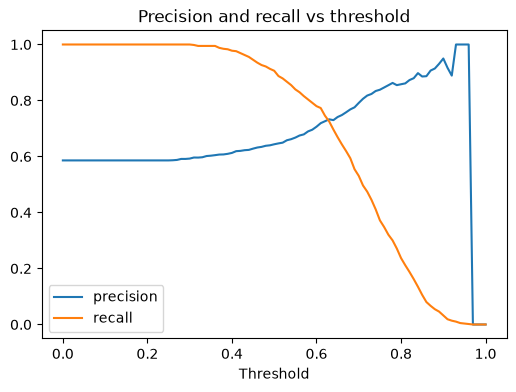

In [7]:
scores = []
for t in np.arange(0.0, 1.01, 0.01):
    predict_positive = (y_pred >= t)
    tp = (predict_positive & (y_val == 1)).sum()
    fp = (predict_positive & (y_val == 0)).sum()
    fn = (~predict_positive & (y_val == 1)).sum()

    precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    scores.append((round(t, 2), precision, recall))

df_scores = pd.DataFrame(scores, columns=['threshold', 'precision', 'recall'])

plt.figure(figsize=(6, 4))
plt.plot(df_scores.threshold, df_scores.precision, label='precision')
plt.plot(df_scores.threshold, df_scores.recall, label='recall')
plt.xlabel('Threshold')
plt.legend()
plt.title('Precision and recall vs threshold')
plt.show()

In [8]:
# On ignore les seuils où les deux métriques valent 0
df_nz = df_scores[(df_scores.precision > 0) | (df_scores.recall > 0)].copy()
df_nz['diff'] = (df_nz.precision - df_nz.recall).abs()
df_nz.loc[df_nz['diff'].idxmin()]

threshold    0.630000
precision    0.732759
recall       0.725256
diff         0.007503
Name: 63, dtype: float64

---
## Question 4 : F1 score

Precision and recall are conflicting - when one grows, the other goes down. That's why they are often combined into the F1 score - a metric that takes into account both.<br>
This is the formula for computing F1:

$$F_1 = 2 \cdot \frac{P \cdot R}{P + R}$$

Where $P$ is precision and $R$ is recall.

Let's compute F1 for all thresholds from 0.0 to 1.0 with increment 0.01.

At which threshold F1 is maximal?
- 0.21
- 0.41
- 0.61
- 0.81

---
## Question 5 : 5-Fold CV

Use the `KFold` class from Scikit-Learn to evaluate our model on 5 different folds:

```python
KFold(n_splits=5, shuffle=True, random_state=1)
```

- Iterate over different folds of `df_full_train`
- Split the data into train and validation
- Train the model on train with these parameters: `LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)`
- Use AUC to evaluate the model on validation

How large is standard deviation of the scores across different folds?
- 0.001
- 0.007
- 0.013
- 0.060

---
## Question 6 : Hyperparameter Tuning

Now let's use 5-Fold cross-validation to find the best parameter `C`.
- Iterate over the following `C` values: `[0.000001, 0.001, 1]`
- Initialize `KFold` with the same parameters as previously
- Use these parameters for the model: `LogisticRegression(solver='liblinear', C=C, max_iter=1000)`
- Compute the mean ROC AUC as well as the std (round the mean and std to 3 decimal digits)

Which `C` leads to the best mean ROC AUC?
- 0.000001
- 0.001
- 1

If you have ties, select the score with the lowest std. If you still have ties, select the smallest `C`.